# Estimation result graphs

Read Excel coefficient tables from `RESULTS_DIR/estimation_results/{base}/` and export
figures to `RESULTS_DIR/graphs/estimation_results/`. Select reference, fine-tuned,
or scaled tables with `TYPE_ESTIMATION`. Only the full sample is used.

The table suffix `_finetune` is used for the `_finetuned` selection. Missing
individual tables are reported; loading stops clearly if no coefficients match.
Boxplots retain the existing convention: significant coefficients only, within
the configured coefficient limits. These boxes are not confidence intervals.

In [42]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.figure import Figure
import os
import re
import importlib
import project_settings
importlib.reload(project_settings)
from project_settings import PATH_WRK, METRIC_SPE, RESULTS_DIR, RUN_DIR, PANEL_CODE_DIR, CHOC_TAG

GRAPHS_DIR = os.path.join(RESULTS_DIR, "graphs", "estimation_results")
os.makedirs(GRAPHS_DIR, exist_ok=True)

# Estimation choice: "" (reference), "_finetuned", or "_scaled".
TYPE_ESTIMATION = ""

# est_all_bases_finetune writes its tables with "_finetune" (without the final d).
# "_finetune" is also accepted directly.
if TYPE_ESTIMATION == "_finetuned":
    ESTIMATION_FILE_SUFFIX = "_finetune"
else:
    ESTIMATION_FILE_SUFFIX = TYPE_ESTIMATION

if ESTIMATION_FILE_SUFFIX not in ("", "_finetune", "_scaled"):
    raise ValueError('TYPE_ESTIMATION must be "", "_finetuned", or "_scaled".')

print(f"Estimation type: {TYPE_ESTIMATION or 'reference'}; table suffix: {ESTIMATION_FILE_SUFFIX!r}")

SECTORS = ["A", "B", "C", "C10_C12", "C13_C15", "C16_C18", "C19", "C20+C21", "C22", "C23",
           "C24", "C25", "C26", "C27", "C28", "C29", "C30", "C31_C33", "D", "E", "F", "G",
           "H", "H49", "H50", "H51", "H52", "H53+J", "I", "K", "L", "M+N", "O+U", "P", "Q",
           "R+S+T"]
BASES = ["FIGARO", "GTAP", "EXIOBASE", "OECD_ICIO", "CAPITAL", "Patents_Citation"]
METRICS = {"dir": "rd_dir_CI", "embod": "rd_embod_CI"}
MODELS = ["rien"]
SUFFIX = {"rien": ""}
COL = {"dir": "(1) rd_dir", "embod": "(1) rd_embod"}
VARIABLES_BY_SPEC = {
    "(1)": ["rd_total"],
    "(2)": ["rd_D", "rd_F"],
    "(3)": ["rd_X", "rd_I"],
    "(4)": ["same_same", "same_diff", "diff_same", "diff_diff"],
}
BASE_MARKERS = {"FIGARO": "o", "GTAP": "s", "EXIOBASE": "^", "OECD_ICIO": "D", "CAPITAL": "P", "Patents_Citation": "X"}
MODEL_COLORS = {"rd_total": "#1f77b1", "rd_X": "#1f77b2", "rd_I": "#00FF5A", "rd_D": "#1f77b4", "rd_F": "#1f77b5", "rd_same_same": "#1f77b6", "rd_same_diff": "#1f77b7", "rd_diff_diff": "#1f77b8", "rd_diff_same": "#1f77b9"}
METRIC_COLORS = {"dir": "#1f77b4", "embod": "#d62728"}
MODEL_LABELS = {"rien": "full sample"}


def metric_files_for(base, metrics=METRICS):
    """Result-file metric name per base, read from METRIC_SPE (e.g. CAPITAL -> rd_dir_CAPITAL, Patents_Citation -> rd_dir_cit)."""
    return {m: METRIC_SPE[f"{base}_{m}"] for m in metrics if f"{base}_{m}" in METRIC_SPE}

def estimation_table_path(base, metric_file, model):
    """Use the same shock and estimation suffix order as the estimation notebooks."""
    return (
        f"{RESULTS_DIR}estimation_results/{base}/tab_{base}_{metric_file}"
        f"{SUFFIX[model]}{CHOC_TAG}{ESTIMATION_FILE_SUFFIX}.xlsx"
    )


# legend names of the knowledge variables
VARIABLE_LABELS = {
    "rd_total": "total_know",
    "rd_D": "national_know", "rd_F": "foreign_know",
    "rd_X": "intersectoral_know", "rd_I": "intrasectoral_know",
    "same_same": "intrasectoral_national_know", "same_diff": "intrasectoral_foreign_know",
    "diff_same": "intersectoral_national_know", "diff_diff": "intersectoral_foreign_know",
}


Estimation type: _scaled; table suffix: '_scaled'


## Figure export and coefficient limits

Create output folders as needed and apply the existing coefficient-range filter.

In [43]:
def export_graph(plot, path, dpi=300):

    if isinstance(plot, tuple):
        fig = plot[0]
    elif isinstance(plot, Figure):
        fig = plot
    else:
        fig = plot.figure

    folder = os.path.dirname(path)
    if folder:
        os.makedirs(folder, exist_ok=True)

    fig.savefig(path, dpi=dpi, bbox_inches="tight")
    return path


def apply_coef_limits(df, coef_min, coef_max, label=""):
    """Drops the coefficients outside [coef_min, coef_max] before anything is computed (None = no limit)."""
    out = df
    if coef_min is not None:
        out = out[out["coef"] >= coef_min]
    if coef_max is not None:
        out = out[out["coef"] <= coef_max]
    if len(out) < len(df):
        print(f"[{label}] {len(df) - len(out)} of {len(df)} coefficients outside [{coef_min}, {coef_max}] left out")
    return out


## Load and parse coefficient tables

Read coefficient values and significance markers. Verify that at least one
matching coefficient is available before plotting.

In [44]:
CELL_RE = re.compile(r"^(-?\d+\.?\d*)\s*\((.+)\)$")


def parse_cell(cell):
    if not isinstance(cell, str) or cell.strip() == "-":
        return None
    m = CELL_RE.match(cell.strip())
    if not m:
        return None
    return float(m.group(1)), m.group(2)


def is_significant_5pct(stars):
    return stars in ("++", "+++", "--", "---")


def load_results(bases, sectors, path_wrk=PATH_WRK, metrics=METRICS, models=MODELS,
                 spec="(1)", variable="rd_total"):
    rows = []
    for base in bases:
        for metric, metric_file in metric_files_for(base, metrics).items():
            for model in models:
                path = estimation_table_path(base, metric_file, model)
                if not os.path.exists(path):
                    print(f"[skipped] no results file for {base} / {metric} / {model}: {path}")
                    continue
                df = pd.read_excel(path, sheet_name="Sheet1").set_index("Secteur")
                col = COL[metric] if spec == "(1)" else f"{spec} {variable}"
                for sector in sectors:
                    if sector not in df.index or col not in df.columns:
                        continue
                    parsed = parse_cell(df.loc[sector, col])
                    if parsed is None:
                        continue
                    coef, stars = parsed
                    rows.append({
                        "sector": sector, "model": model, "base": base, "metric": metric,
                        "coef": coef, "stars": stars, "significant": is_significant_5pct(stars),
                    })
    if not rows:
        raise ValueError(
            f"No matching estimation coefficients found in {RESULTS_DIR}estimation_results/. "
            "Check the available Excel files, TYPE_ESTIMATION, bases, sectors, and specification."
        )
    return pd.DataFrame(rows)


## Coefficients by sector and database

Define the plot, then select a specification, variables, and sectors in the next cell.

In [45]:
def plot_results(df, bases, sectors, models=MODELS, metrics=METRICS,
                  spec="(1)", variable="rd_total", title=None,
                  box_width=None, jitter=None, figsize=(12, 6), seed=0, xtick_rotation=45,
                  coef_min=-1.0, coef_max=0.5):
    rng = np.random.default_rng(seed)
    df = apply_coef_limits(df, coef_min, coef_max, "plot_results")
    n_models = len(models)
    model_width = 0.8 / n_models
    if box_width is None:
        box_width = model_width * 0.8 if n_models > 1 else 0.7
    if jitter is None:
        jitter = model_width * 0.15 if n_models > 1 else 0.22
    jit = jitter
    if title is None:
        title = f"Unit cost elasticity to R&D Knowledge stock (model 1: total_know) by sector, model, base and metric"
    if n_models == 1:
        title = f"{title}\nModel: {MODEL_LABELS[models[0]]}"

    fig, ax = plt.subplots(figsize=figsize)
    xticks, xticklabels = [], []

    for si, sector in enumerate(sectors):
        if n_models > 1:
            ax.text(si, -0.2, sector, transform=ax.get_xaxis_transform(), ha="center", va="top",
                    fontsize=10, fontweight="bold")
        for mi, model in enumerate(models):
            center = si + (mi - (n_models - 1) / 2) * model_width
            sub = df[(df["sector"] == sector) & (df["model"] == model)]
            xticks.append(center)
            xticklabels.append(sector if n_models == 1 else MODEL_LABELS[model])
            if sub.empty:
                continue

            sig_vals = sub.loc[sub["significant"], "coef"].values
            if len(sig_vals) > 0:   # box computed on significant values only
                ax.boxplot(
                    sig_vals, positions=[center], widths=box_width,
                    showfliers=False, patch_artist=True,
                    boxprops=dict(facecolor="none", edgecolor="black", linewidth=1),
                    medianprops=dict(color="black"), whiskerprops=dict(color="black"),
                    capprops=dict(color="black"), zorder=2,
                )

            nonsig = sub[~sub["significant"]]
            if not nonsig.empty:
                j = rng.uniform(-jit, jit, size=len(nonsig))
                ax.scatter(center + j, nonsig["coef"], color="gray", alpha=0.3,
                           s=25, zorder=1, edgecolors="none", label="_nolegend_")

            sig = sub[sub["significant"]]
            for base in bases:
                for metric in metrics:
                    pts = sig[(sig["base"] == base) & (sig["metric"] == metric)]
                    if pts.empty:
                        continue
                    j = rng.uniform(-jit, jit, size=len(pts))
                    ax.scatter(
                        center + j, pts["coef"], color=METRIC_COLORS[metric],
                        marker=BASE_MARKERS[base], s=60, zorder=3,
                        edgecolors="black", linewidths=0.5, label="_nolegend_",
                    )

    ax.axhline(0, color="black", linewidth=0.7, linestyle="--", zorder=0)
    for k in range(1, len(sectors)):
        ax.axvline(k - 0.5, color="gray", linestyle=":", linewidth=0.8, alpha=0.6, zorder=0)
    ax.set_xticks(xticks)
    ax.set_xticklabels(xticklabels, fontsize=8, rotation=xtick_rotation, ha="right", rotation_mode="anchor")
    ax.set_ylabel(f"Estimated coefficient (spec. {spec[1]}: {variable})")
    ax.set_title(title)

    from matplotlib.lines import Line2D
    legend_handles = (
        [Line2D([0], [0], marker="s", color="none", markerfacecolor=METRIC_COLORS[m],
                markeredgecolor="black", markersize=9, label=m) for m in metrics]
        + [Line2D([0], [0], marker=BASE_MARKERS[b], color="none", markerfacecolor="white",
                  markeredgecolor="black", markersize=9, label=b) for b in bases]
        + [Line2D([0], [0], marker="o", color="none", markerfacecolor="gray", alpha=0.5,
                  markeredgecolor="none", markersize=9, label="not significant (>5%)")]
    )
    ax.legend(handles=legend_handles, loc="upper center", bbox_to_anchor=(0.5, -0.3 if n_models > 1 else -0.18),
              ncol=min(len(legend_handles), 5))

    fig.tight_layout()
    return fig, ax


[plot_results] 11 of 176 coefficients outside [-1.0, 0.5] left out


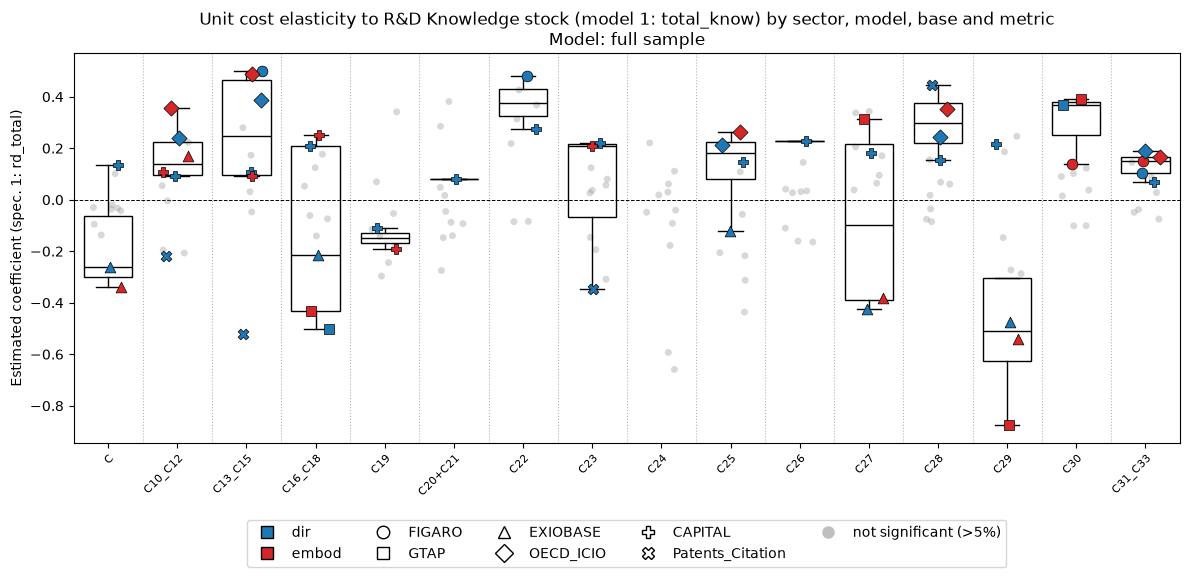

In [46]:
BASES = ["FIGARO", "GTAP", "EXIOBASE", "OECD_ICIO", "CAPITAL", "Patents_Citation"]
SECTORS = ["C", "C10_C12", "C13_C15", "C16_C18", "C19", "C20+C21", "C22", "C23",
           "C24", "C25", "C26", "C27", "C28", "C29", "C30", "C31_C33"]

MODEL_CHOICE = "all"   # Full sample only.
SPEC = "(1)" # (1), (2), (3), or (4)
VARIABLE = None
MODEL_ALIASES = {"all": "rien", "tout": "rien", "rien": "rien"}
models_to_plot = [MODEL_ALIASES[MODEL_CHOICE]]
variables = VARIABLES_BY_SPEC[SPEC] if VARIABLE is None else [VARIABLE]

for var in variables:
    df_results = load_results(bases=BASES,sectors=SECTORS, spec=SPEC, variable=var)
    fig, ax = plot_results(df_results, bases=BASES, sectors=SECTORS, models=models_to_plot, spec=SPEC, variable=var, box_width=None, jitter=None)
    export_graph((fig, ax), os.path.join(GRAPHS_DIR, f"rd_coefficient_{var}{TYPE_ESTIMATION}.png"))
    plt.show()


## Four-channel results

Load all coefficient columns, then compare the four origin channels across databases.

In [47]:
CHANNEL_LABELS = {
    "same_same": "same sector\nsame country",
    "same_diff": "same sector\nforeign country",
    "diff_same": "other sector\nsame country",
    "diff_diff": "other sector\nforeign country",
}


def load_all_results(bases, path_wrk=PATH_WRK, metrics=METRICS, models=MODELS):
    rows = []
    for base in bases:
        for metric, metric_file in metric_files_for(base, metrics).items():
            for model in models:
                path = estimation_table_path(base, metric_file, model)
                if not os.path.exists(path):
                    print(f"[skipped] no results file for {base} / {metric} / {model}: {path}")
                    continue
                df = pd.read_excel(path, sheet_name="Sheet1").set_index("Secteur")
                for sector in df.index:
                    for col in df.columns:
                        if "Ck-wl" in col:
                            continue
                        parsed = parse_cell(df.loc[sector, col])
                        if parsed is None:
                            continue
                        spec, var = col.split(" ", 1)
                        coef, stars = parsed
                        rows.append({
                            "sector": sector, "model": model, "base": base, "metric": metric,
                            "spec": spec, "var": var, "coef": coef, "stars": stars,
                            "significant": is_significant_5pct(stars),
                        })
    if not rows:
        raise ValueError(
            f"No usable estimation coefficients found in {RESULTS_DIR}estimation_results/. "
            "Check the available Excel files and TYPE_ESTIMATION."
        )
    out = pd.DataFrame(rows)
    out["var"] = out["var"].replace({"rd_dir": "rd_total", "rd_embod": "rd_total"})
    out["effect"] = np.where(~out["significant"], "ns", np.where(out["coef"] < 0, "neg", "pos"))
    return out


df_all = load_all_results(bases=BASES)
SECTOR_ORDER = list(dict.fromkeys(df_all["sector"]))
df_all.groupby(["model", "base", "metric"]).size().unstack("model")


model                    rien
base             metric      
CAPITAL          dir      222
                 embod    360
EXIOBASE         dir      360
                 embod    360
FIGARO           dir      360
                 embod    360
GTAP             dir      360
                 embod    360
OECD_ICIO        dir      356
                 embod    356
Patents_Citation dir      180

In [48]:
def plot_channels(df, bases, model="rien", metrics=METRICS, channels=CHANNEL_LABELS,
                  sectors=None, annotate="sig",
                  ylim=None, ylim_margin=0.05, figsize=(17, 5.5), seed=0, xtick_rotation=45,
                  coef_min=-1.0, coef_max=0.5):
    rng = np.random.default_rng(seed)
    df = apply_coef_limits(df, coef_min, coef_max, "plot_channels")
    if ylim is None:
        data = df[(df["model"] == model) & (df["spec"] == "(4)") & df["base"].isin(bases)
                  & df["metric"].isin(metrics) & df["var"].isin(channels)]
        if sectors is not None:
            data = data[data["sector"].isin(sectors)]
        significant_data = data[data["significant"]]
        if not significant_data.empty:
            data = significant_data
        if data.empty:
            ylim = (-0.1, 0.1)
        else:
            lo, hi = data["coef"].min(), data["coef"].max()
            pad = ylim_margin * (hi - lo if hi > lo else max(abs(lo), 1.0))
            ylim = (lo - pad, hi + pad)
    fig, axes = plt.subplots(1, len(bases), figsize=figsize, sharey=True)
    metric_list = list(metrics)
    width = 0.8 / len(metric_list)

    for ax, base in zip(np.atleast_1d(axes), bases):
        sub = df[(df["model"] == model) & (df["spec"] == "(4)") & (df["base"] == base)]
        if sectors is not None:
            sub = sub[sub["sector"].isin(sectors)]
        for ci, channel in enumerate(channels):
            for mi, metric in enumerate(metric_list):
                s = sub[(sub["var"] == channel) & (sub["metric"] == metric)]
                if s.empty:
                    continue
                center = ci + (mi - (len(metric_list) - 1) / 2) * width
                sig_vals = s.loc[s["significant"], "coef"].values
                if len(sig_vals) > 0:   # box computed on significant values only
                    ax.boxplot(sig_vals, positions=[center], widths=width * 0.85,
                               showfliers=False, patch_artist=True,
                               boxprops=dict(facecolor="none", edgecolor="#555555", linewidth=1),
                               medianprops=dict(color="#222222", linewidth=1.5),
                               whiskerprops=dict(color="#555555"),
                               capprops=dict(color="#555555"), zorder=2)
                ns, sg = s[~s["significant"]], s[s["significant"]]
                x_ns = center + rng.uniform(-width * 0.25, width * 0.25, len(ns))
                x_sg = center + rng.uniform(-width * 0.25, width * 0.25, len(sg))
                if annotate in ("sig", "all"):
                    for x, y, name in zip(x_sg, sg["coef"], sg["sector"]):
                        ax.text(x, y, name, color=METRIC_COLORS[metric], fontsize=6.5, fontweight="bold",
                                ha="center", va="center", zorder=4)
                else:
                    ax.scatter(x_sg, sg["coef"], color=METRIC_COLORS[metric], marker=BASE_MARKERS[base],
                               s=40, edgecolors="black", linewidths=0.4, zorder=3)
                if annotate == "all":
                    for x, y, name in zip(x_ns, ns["coef"], ns["sector"]):
                        ax.text(x, y, name, color="gray", alpha=0.45, fontsize=6, ha="center", va="center", zorder=1)
                else:
                    ax.scatter(x_ns, ns["coef"], color="gray", alpha=0.3, s=18, edgecolors="none", zorder=1)

        ax.axhline(0, color="black", linewidth=0.7, linestyle="--", zorder=0)
        for k in range(1, len(channels)):
            ax.axvline(k - 0.5, color="gray", linestyle=":", linewidth=0.8, alpha=0.6, zorder=0)
        ax.set_xticks(range(len(channels)))
        ax.set_xticklabels(list(channels.values()), fontsize=8, rotation=xtick_rotation, ha="right", rotation_mode="anchor")
        ax.set_title(base)
        ax.set_ylim(*ylim)

    np.atleast_1d(axes)[0].set_ylabel("Estimated coefficient (spec. 4), one point per sector")
    from matplotlib.lines import Line2D
    handles = [Line2D([0], [0], marker="s", color="none", markerfacecolor=METRIC_COLORS[m],
                      markeredgecolor="black", markersize=9, label=m) for m in metric_list]
    handles.append(Line2D([0], [0], marker="o", color="none", markerfacecolor="gray", alpha=0.5,
                          markeredgecolor="none", markersize=9, label="not significant (>5%)"))
    fig.legend(handles=handles, loc="lower center", ncol=3, bbox_to_anchor=(0.5, -0.09))
    fig.suptitle(f"Unit cost elasticity to R&D Knowledge stock (model 4, {MODEL_LABELS[model]}) — "
                 "domestic/foreign origin × same/other sector")
    fig.tight_layout()
    return fig, axes

[plot_channels] 113 of 3634 coefficients outside [-1.0, 0.5] left out


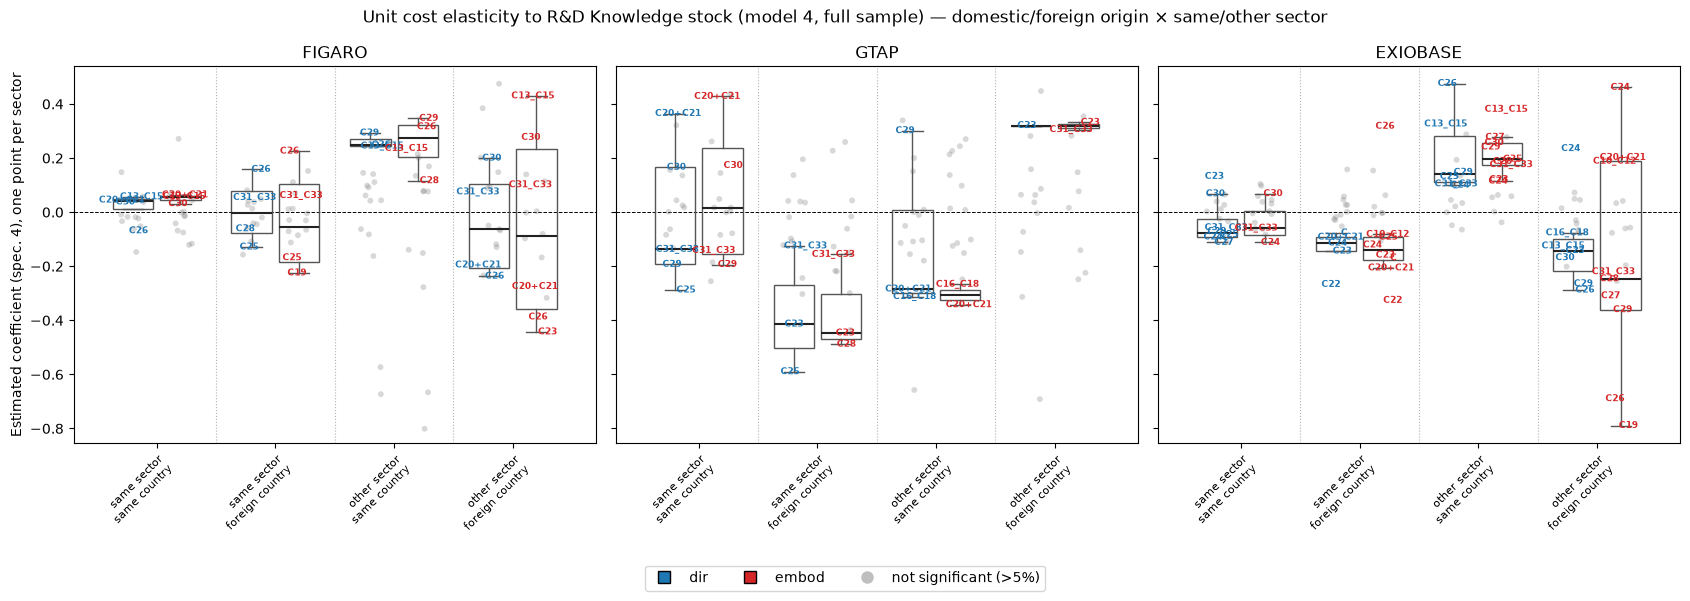

In [49]:
BASES = ["FIGARO", "GTAP", "EXIOBASE"]

CHANNEL_SECTORS = ["C", "C10_C12", "C13_C15", "C16_C18", "C19", "C20+C21", "C22", "C23",
           "C24", "C25", "C26", "C27", "C28", "C29", "C30", "C31_C33"]    # None = every sector, or a list such as ["C24", "C27", "C29", "G", "H50"]

fig, axes = plot_channels(df_all, bases=BASES, sectors=CHANNEL_SECTORS, annotate="sig")
export_graph((fig, axes), os.path.join(GRAPHS_DIR, f"channels_spec4_part1{TYPE_ESTIMATION}.png"))
plt.show()

[plot_channels] 113 of 3634 coefficients outside [-1.0, 0.5] left out


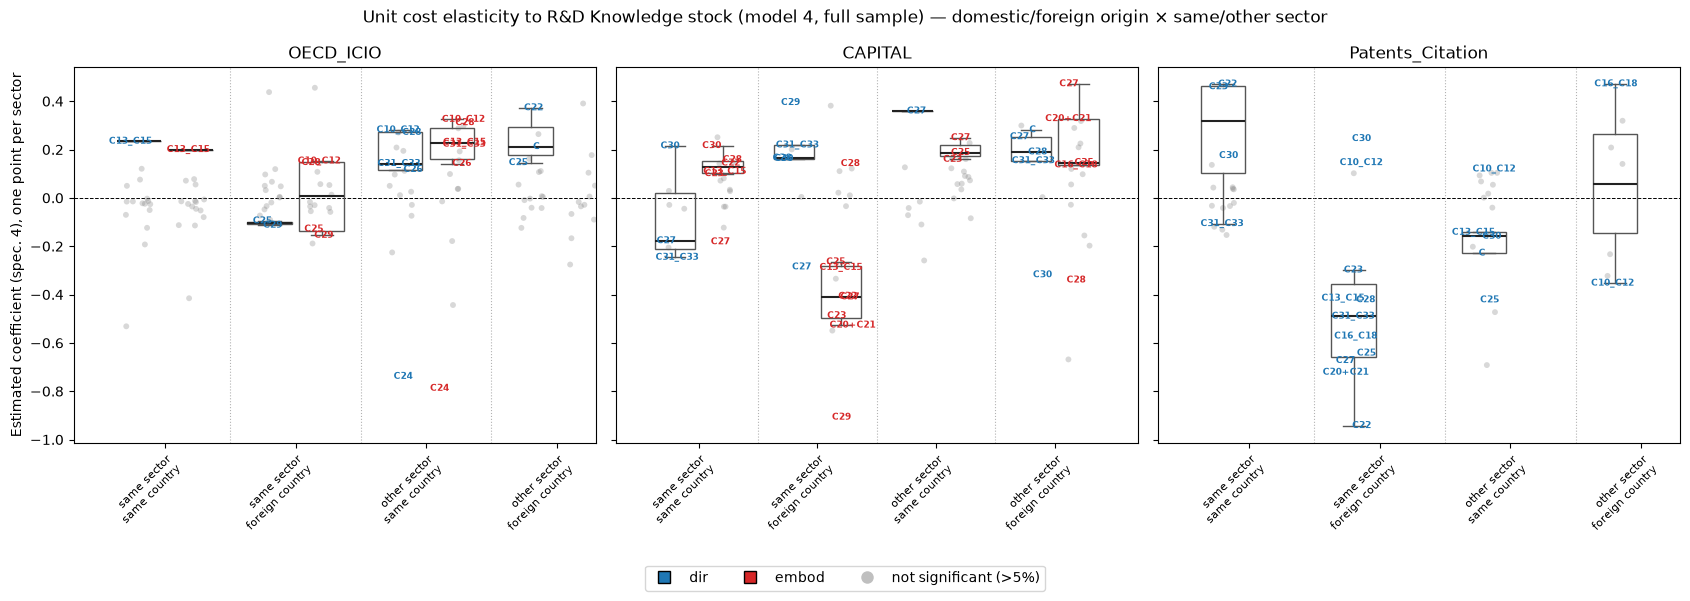

In [50]:
BASES = ["OECD_ICIO", "CAPITAL", "Patents_Citation"]

CHANNEL_SECTORS = ["C", "C10_C12", "C13_C15", "C16_C18", "C19", "C20+C21", "C22", "C23",
           "C24", "C25", "C26", "C27", "C28", "C29", "C30", "C31_C33"]    # None = every sector, or a list such as ["C24", "C27", "C29", "G", "H50"]

fig, axes = plot_channels(df_all, bases=BASES, sectors=CHANNEL_SECTORS, annotate="sig")
export_graph((fig, axes), os.path.join(GRAPHS_DIR, f"channels_spec4_part2{TYPE_ESTIMATION}.png"))
plt.show()

## Polar coefficient plots

Display selected sector coefficients on a radial axis, using the same input tables.

In [51]:
def plot_polar(df, bases, sectors, model="rien", metrics=METRICS, spec="(1)", variable="rd_total",
               coef_min=-1.0, coef_max=0.5, title=None, figsize=(10, 10), jitter=0.3, seed=0, show_metric=True):
    rng = np.random.default_rng(seed)
    point_color = lambda metric: METRIC_COLORS[metric] if show_metric else "#34495e"   # one colour when dir/embod are not split
    data = df[df["model"] == model]
    n_before = len(data)
    if coef_min is not None:
        data = data[data["coef"] >= coef_min]
    if coef_max is not None:
        data = data[data["coef"] <= coef_max]
    if n_before > len(data):
        print(f"[plot_polar] {n_before - len(data)} of {n_before} coefficients outside [{coef_min}, {coef_max}] left out")
    lo, hi = data["coef"].min(), data["coef"].max()
    pad = 0.08 * (hi - lo)
    lo, hi = lo - pad, hi + pad
    n = len(sectors)
    step = 2 * np.pi / n
    theta = np.arange(n) * step

    def r(v):
        # return hi - np.asarray(v, dtype=float)      # inverted axis: highest value at the centre
        return np.asarray(v, dtype=float) - lo

    fig = plt.figure(figsize=figsize)
    ax = fig.add_subplot(111, projection="polar")
    ax.set_theta_zero_location("N")
    ax.set_theta_direction(-1)

    ax.plot(np.linspace(0, 2 * np.pi, 300), np.full(300, r(0)), color="black", linewidth=0.8,
            linestyle="--", zorder=1)
    for k in range(n):
        a = theta[k] + step / 2
        ax.plot([a, a], [0, hi - lo], color="gray", linestyle=":", linewidth=0.8, alpha=0.6, zorder=0)

    for si, sector in enumerate(sectors):
        sub = data[data["sector"] == sector]
        if sub.empty:
            continue
        vals = sub.loc[sub["significant"], "coef"]   # box computed on significant values only
        t, half = theta[si], step * 0.28
        if len(vals) > 0:
            q1, med, q3 = np.percentile(vals, [25, 50, 75])
            iqr = q3 - q1
            w_lo, w_hi = vals[vals >= q1 - 1.5 * iqr].min(), vals[vals <= q3 + 1.5 * iqr].max()
            ax.plot([t, t], r([w_lo, w_hi]), color="black", linewidth=1, zorder=2)
            ax.bar(t, q3 - q1, width=2 * half, bottom=r(q1), facecolor="none", edgecolor="black",
                   linewidth=1, zorder=2)
            arc = np.linspace(t - half, t + half, 20)
            ax.plot(arc, np.full(20, r(med)), color="black", linewidth=1.8, zorder=2)

        nonsig = sub[~sub["significant"]]
        ax.scatter(t + rng.uniform(-step * jitter, step * jitter, len(nonsig)),
                   r(nonsig["coef"]), color="gray", alpha=0.3, s=25, edgecolors="none", zorder=1)
        sig = sub[sub["significant"]]
        for base in bases:
            for metric in metrics:
                pts = sig[(sig["base"] == base) & (sig["metric"] == metric)]
                if pts.empty:
                    continue
                ax.scatter(t + rng.uniform(-step * jitter, step * jitter, len(pts)), r(pts["coef"]),
                           color=point_color(metric), marker=BASE_MARKERS[base], s=55, zorder=3,
                           edgecolors="black", linewidths=0.5)

    from matplotlib.ticker import MaxNLocator
    ticks = [t for t in MaxNLocator(6).tick_values(lo, hi) if lo <= t <= hi]
    ticks = sorted(ticks, reverse=False)
    ax.set_ylim(0, hi - lo)
    ax.set_yticks(r(ticks))
    ax.set_yticklabels([f"{t:.2f}" for t in ticks], fontsize=7)
    ax.grid(False)
    ax.set_rlabel_position(np.degrees(step / 2))
    ax.set_xticks(theta)
    ax.set_xticklabels(sectors, fontsize=8)

    if title is None:
        title = (f"Unit cost elasticity to R&D Knowledge stock (model {spec[1]}: {VARIABLE_LABELS.get(variable, variable)}), "
                 f"{MODEL_LABELS[model]}\n"
                 "dashed ring = 0 ; inward = negative (lower unit cost)")
    ax.set_title(title, pad=24)

    from matplotlib.lines import Line2D
    handles = (
        ([Line2D([0], [0], marker="s", color="none", markerfacecolor=METRIC_COLORS[m],
                 markeredgecolor="black", markersize=9, label=m) for m in metrics] if show_metric else [])
        + [Line2D([0], [0], marker=BASE_MARKERS[b], color="none", markerfacecolor="white",
                  markeredgecolor="black", markersize=9, label=b) for b in bases]
        + [Line2D([0], [0], marker="o", color="none", markerfacecolor="gray", alpha=0.5,
                  markeredgecolor="none", markersize=9, label="not significant (>5%)")]
    )
    ax.legend(handles=handles, loc="upper center", bbox_to_anchor=(0.5, -0.08), ncol=min(len(handles), 5))
    fig.tight_layout()
    return fig, ax


[plot_polar] 11 of 176 coefficients outside [-1.0, 0.5] left out


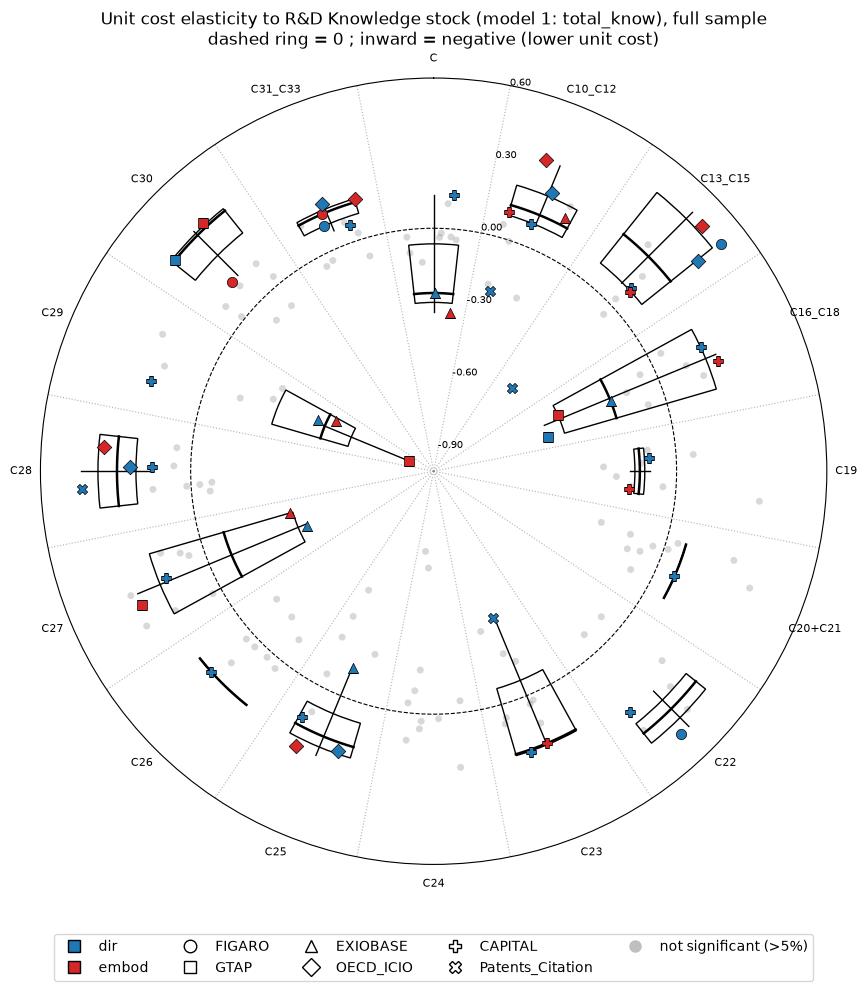

In [52]:
BASES = ["FIGARO", "GTAP", "EXIOBASE", "OECD_ICIO", "CAPITAL", "Patents_Citation"]
SECTORS = ["C", "C10_C12", "C13_C15", "C16_C18", "C19", "C20+C21", "C22", "C23",
           "C24", "C25", "C26", "C27", "C28", "C29", "C30", "C31_C33"]

POLAR_MODEL = "all"   # Full sample only.
POLAR_SPEC = "(1)"    # (1), (2), (3) or (4)

COEF_MIN, COEF_MAX = -1.0, 0.5   # coefficients outside this range are ignored (None = no limit)

polar_model = {"all": "rien", "tout": "rien", "rien": "rien"}[POLAR_MODEL]
for var in VARIABLES_BY_SPEC[POLAR_SPEC]:
    df_polar = load_results(bases=BASES, sectors=SECTORS, models=[polar_model], spec=POLAR_SPEC, variable=var)
    fig, ax = plot_polar(df_polar, bases=BASES, sectors=SECTORS, model=polar_model, spec=POLAR_SPEC, variable=var,
                         coef_min=COEF_MIN, coef_max=COEF_MAX)
    export_graph((fig, ax), os.path.join(GRAPHS_DIR, f"polar_{polar_model}_{var}{TYPE_ESTIMATION}.png"))
    plt.show()


## Compare knowledge variables

Plot domestic/foreign, same/other-sector, or four-channel coefficients together.

In [53]:
VARIABLE_COLORS = {"rd_total": "#1b9e77", "rd_D": "#006FFF", "rd_F": "#FF0000", "rd_X": "#FD6BFF",
                   "rd_I": "#00FF5A", "same_same": "#e6ab02", "same_diff": "#a6761d",
                   "diff_same": "#17becf", "diff_diff": "#e41a1c"}
METRIC_SHAPES = {"dir": "o", "embod": "^"}
VARIABLE_SPEC = {v: spec for spec, vs in VARIABLES_BY_SPEC.items() for v in vs}


def load_results_variables(bases, sectors, variables, models=MODELS, metrics=METRICS):
    frames = []
    for v in variables:
        d = load_results(bases=bases, sectors=sectors, metrics=metrics, models=models,
                         spec=VARIABLE_SPEC[v], variable=v)
        d["variable"] = v
        frames.append(d)
    return pd.concat(frames, ignore_index=True)


def plot_results_by_variable(df, bases, sectors, variables, model="rien", metrics=METRICS,
                             box_by_variable=False, box_by_spec=False, title=None, box_width=None, jitter=None,
                             figsize=(13, 6), seed=0, xtick_rotation=45,
                  coef_min=-1.0, coef_max=0.5, show_metric=False,
                  ax=None, draw_legend=True, show_xticklabels=True):
    rng = np.random.default_rng(seed)
    df = apply_coef_limits(df, coef_min, coef_max, "plot_results_by_variable")
    data = df[(df["model"] == model) & df["base"].isin(bases) & df["variable"].isin(variables)]
    n_var = len(variables)
    specs_present = list(dict.fromkeys(VARIABLE_SPEC[v] for v in variables))
    n_groups = n_var if box_by_variable else (len(specs_present) if box_by_spec else 1)
    slot = 0.8 / n_groups if n_groups > 1 else 1.0
    if box_width is None:
        box_width = slot * 0.8 if n_groups > 1 else 0.7
    if jitter is None:
        jitter = slot * (0.3 if box_by_spec and not box_by_variable else 0.15) if n_groups > 1 else 0.22
    if title is None:
        title = ("Unit cost elasticity to R&D Knowledge stock by sector and type of knowledge (all bases pooled)\n"
                 f"Model: {MODEL_LABELS[model]}")

    own_fig = ax is None
    if own_fig:
        fig, ax = plt.subplots(figsize=figsize)
    else:
        fig = ax.figure
    xticks, xticklabels = [], []

    for si, sector in enumerate(sectors):
        sdata = data[data["sector"] == sector]
        if box_by_variable:
            groups = [(si + (vi - (n_var - 1) / 2) * slot, sdata[sdata["variable"] == v])
                      for vi, v in enumerate(variables)]
            xticks += [c for c, _ in groups]
            xticklabels += list(variables)
            ax.text(si, -0.13, sector, transform=ax.get_xaxis_transform(), ha="center", va="top",
                    fontsize=10, fontweight="bold")
        elif box_by_spec:
            # one box per specification (e.g. (2) = rd_D + rd_F, (3) = rd_X + rd_I), side by side under the sector name
            groups = [(si + (gi - (len(specs_present) - 1) / 2) * slot,
                       sdata[sdata["variable"].map(VARIABLE_SPEC) == sp])
                      for gi, sp in enumerate(specs_present)]
            xticks.append(si)
            xticklabels.append(sector)
        else:
            groups = [(si, sdata)]
            xticks.append(si)
            xticklabels.append(sector)

        for center, sub in groups:
            if sub.empty:
                continue
            sig_vals = sub.loc[sub["significant"], "coef"].values
            if len(sig_vals) > 0:   # box computed on significant values only
                ax.boxplot(
                    sig_vals, positions=[center], widths=box_width,
                    showfliers=False, patch_artist=True,
                    boxprops=dict(facecolor="none", edgecolor="black", linewidth=1),
                    medianprops=dict(color="black"), whiskerprops=dict(color="black"),
                    capprops=dict(color="black"), zorder=2,
                )
            nonsig = sub[~sub["significant"]]
            if not nonsig.empty:
                ax.scatter(center + rng.uniform(-jitter, jitter, len(nonsig)), nonsig["coef"],
                           color="gray", alpha=0.3, s=25, zorder=1, edgecolors="none")
            sig = sub[sub["significant"]]
            for var in variables:
                for metric in metrics:
                    pts = sig[(sig["variable"] == var) & (sig["metric"] == metric)]
                    if pts.empty:
                        continue
                    ax.scatter(center + rng.uniform(-jitter, jitter, len(pts)), pts["coef"],
                               color=VARIABLE_COLORS[var], marker=METRIC_SHAPES[metric] if show_metric else "o", s=60,
                               zorder=3, edgecolors="black", linewidths=0.5)

    ax.axhline(0, color="black", linewidth=0.7, linestyle="--", zorder=0)
    for k in range(1, len(sectors)):
        ax.axvline(k - 0.5, color="gray", linestyle=":", linewidth=0.8, alpha=0.6, zorder=0)
    ax.set_xticks(xticks)
    ax.set_xticklabels(xticklabels, fontsize=8 if not box_by_variable else 7, rotation=xtick_rotation, ha="right", rotation_mode="anchor")
    if not show_xticklabels:
        ax.tick_params(labelbottom=False)
    ax.set_ylabel("Estimated coefficient")
    ax.set_title(title)
    variable_labels = VARIABLE_LABELS
    from matplotlib.lines import Line2D
    handles = (
        [Line2D([0], [0], marker="s", color="none", markerfacecolor=VARIABLE_COLORS[v],
                markeredgecolor="black", markersize=9, label=variable_labels.get(v, v)) for v in variables]
        + ([Line2D([0], [0], marker=METRIC_SHAPES[m], color="none", markerfacecolor="white",
                   markeredgecolor="black", markersize=9, label=m) for m in metrics] if show_metric else [])
        + [Line2D([0], [0], marker="o", color="none", markerfacecolor="gray", alpha=0.5,
                  markeredgecolor="none", markersize=9, label="not significant (>5%)")]
    )
    if draw_legend:
        ax.legend(handles=handles, loc="upper center", bbox_to_anchor=(0.5, -0.3 if box_by_variable else -0.18),
                  ncol=min(len(handles), 5))
    if own_fig:
        fig.tight_layout()
    return fig, ax


[plot_results_by_variable] 34 of 686 coefficients outside [-1.0, 0.5] left out


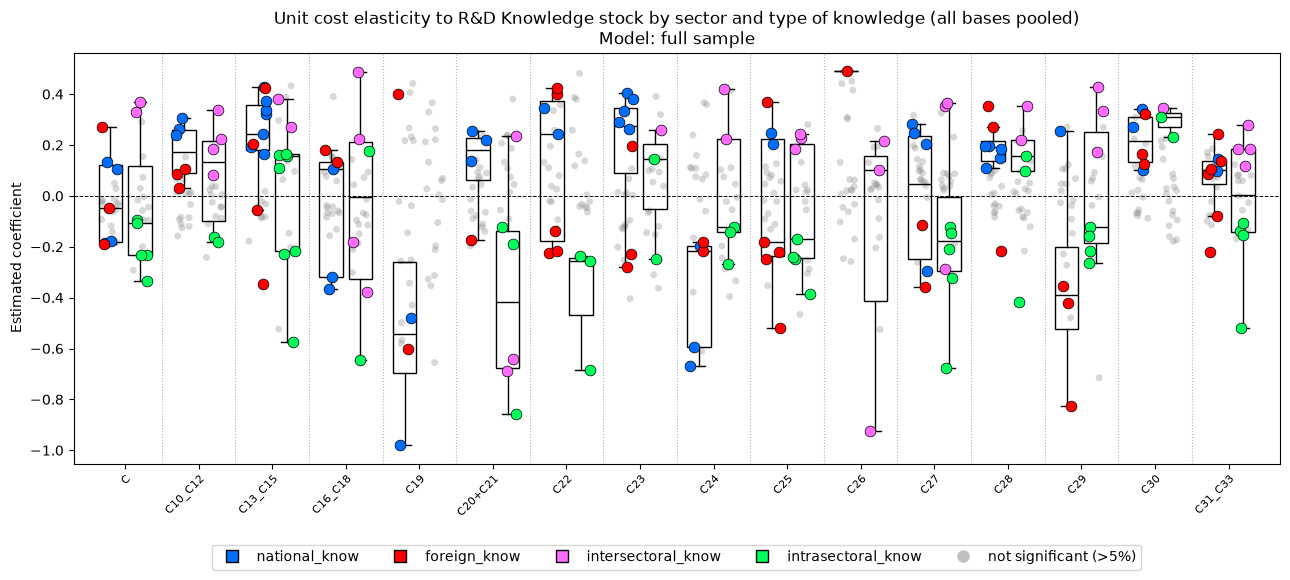

In [54]:
SECTORS = ["C", "C10_C12", "C13_C15", "C16_C18", "C19", "C20+C21", "C22", "C23",
           "C24", "C25", "C26", "C27", "C28", "C29", "C30", "C31_C33"]

VAR_VARIABLES = ["rd_D", "rd_F", "rd_X", "rd_I"]   # any of VARIABLE_COLORS: rd_total, rd_D, rd_F, rd_X, rd_I, same_same, same_diff, diff_same, diff_diff
VAR_MODEL = "all"            # Full sample only.
VAR_BOX_BY_VARIABLE = False  # False = one box per sector ; True = one box per (sector, variable)
VAR_BOX_BY_SPEC = True      # True = one box per specification ((2) vs (3)), side by side, same x position

var_model = {"all": "rien", "tout": "rien", "rien": "rien"}[VAR_MODEL]
df_var = load_results_variables(BASES, SECTORS, VAR_VARIABLES, models=[var_model])
fig, ax = plot_results_by_variable(df_var, bases=BASES, sectors=SECTORS, variables=VAR_VARIABLES,
                                   model=var_model, box_by_variable=VAR_BOX_BY_VARIABLE, box_by_spec=VAR_BOX_BY_SPEC)
export_graph((fig, ax), os.path.join(GRAPHS_DIR, f"rd_variables_{var_model}_part1{TYPE_ESTIMATION}.png"))
plt.show()


[plot_results_by_variable] 33 of 668 coefficients outside [-1.0, 0.5] left out


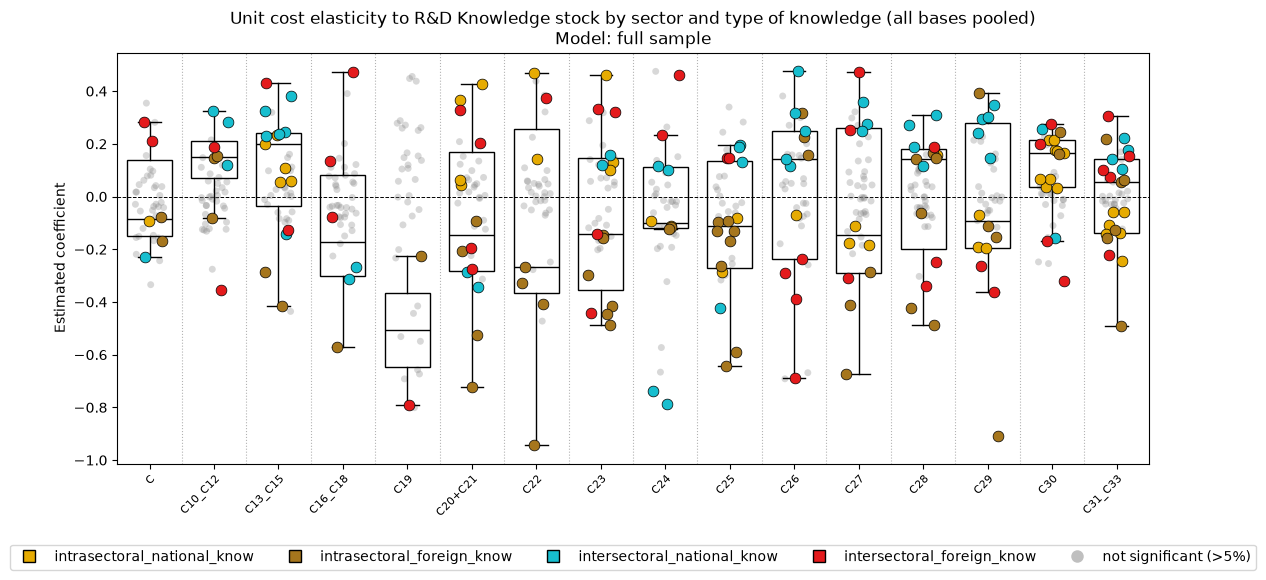

In [55]:
SECTORS = ["C", "C10_C12", "C13_C15", "C16_C18", "C19", "C20+C21", "C22", "C23",
           "C24", "C25", "C26", "C27", "C28", "C29", "C30", "C31_C33"]

VAR_VARIABLES = ["same_same", "same_diff", "diff_same", "diff_diff"]   # any of VARIABLE_COLORS: rd_total, rd_D, rd_F, rd_X, rd_I, same_same, same_diff, diff_same, diff_diff
VAR_MODEL = "all"            # Full sample only.
VAR_BOX_BY_VARIABLE = False  # False = one box per sector ; True = one box per (sector, variable)
VAR_BOX_BY_SPEC = False      # True = one box per specification ((2) vs (3)), side by side, same x position

var_model = {"all": "rien", "tout": "rien", "rien": "rien"}[VAR_MODEL]
df_var = load_results_variables(BASES, SECTORS, VAR_VARIABLES, models=[var_model])
fig, ax = plot_results_by_variable(df_var, bases=BASES, sectors=SECTORS, variables=VAR_VARIABLES,
                                   model=var_model, box_by_variable=VAR_BOX_BY_VARIABLE, box_by_spec=VAR_BOX_BY_SPEC)
export_graph((fig, ax), os.path.join(GRAPHS_DIR, f"rd_variables_{var_model}_part2{TYPE_ESTIMATION}.png"))
plt.show()


## Stacked specification comparison

Place specifications (2) and (3) above specification (4), with a shared sector axis.

In [56]:
def plot_variables_stacked(df_top, df_bottom, bases, sectors, variables_top, variables_bottom,
                           model="rien", box_by_spec_top=True, box_by_spec_bottom=False,
                           coef_min=-1.0, coef_max=0.5, show_metric=False, title=None,
                           figsize=(13, 9), height_ratios=(1, 1), xtick_rotation=45, seed=0):
    """Two plot_results_by_variable graphs glued together (top / bottom, shared x axis, no gap)
    with a single legend below. Typically top = models 2 and 3, bottom = model 4."""
    from matplotlib.lines import Line2D
    from matplotlib.ticker import FuncFormatter

    fig, (ax_top, ax_bottom) = plt.subplots(2, 1, sharex=True, figsize=figsize,
                                            gridspec_kw={"hspace": 0.0, "height_ratios": list(height_ratios)})
    if title is None:
        title = ("Unit cost elasticity to R&D Knowledge stock by sector and type of knowledge (all bases pooled)\n"
                 f"Model: {MODEL_LABELS[model]}")
    common = dict(bases=bases, sectors=sectors, model=model, coef_min=coef_min, coef_max=coef_max,
                  show_metric=show_metric, xtick_rotation=xtick_rotation, seed=seed, draw_legend=False)
    plot_results_by_variable(df_top, variables=variables_top, box_by_spec=box_by_spec_top, ax=ax_top,
                             show_xticklabels=False, title=title, **common)
    plot_results_by_variable(df_bottom, variables=variables_bottom, box_by_spec=box_by_spec_bottom, ax=ax_bottom,
                             title="", **common)
    ax_top.set_ylabel("Estimated coefficient (models 2 and 3)")
    ax_bottom.set_ylabel("Estimated coefficient (model 4)")

    def hide_edge_label(ax, edge):
        """Hides the y tick label closest to the junction so the two graphs' labels do not collide."""
        def fmt(v, pos):
            lo, hi = ax.get_ylim()
            tol = 0.05 * (hi - lo)
            if (edge == "lower" and v <= lo + tol) or (edge == "upper" and v >= hi - tol):
                return ""
            return f"{v:g}"
        ax.yaxis.set_major_formatter(FuncFormatter(fmt))

    hide_edge_label(ax_top, "lower")
    hide_edge_label(ax_bottom, "upper")

    all_variables = list(variables_top) + list(variables_bottom)
    handles = (
        [Line2D([0], [0], marker="s", color="none", markerfacecolor=VARIABLE_COLORS[v],
                markeredgecolor="black", markersize=9, label=VARIABLE_LABELS.get(v, v)) for v in all_variables]
        + ([Line2D([0], [0], marker=METRIC_SHAPES[m], color="none", markerfacecolor="white",
                   markeredgecolor="black", markersize=9, label=m) for m in METRICS] if show_metric else [])
        + [Line2D([0], [0], marker="o", color="none", markerfacecolor="gray", alpha=0.5,
                  markeredgecolor="none", markersize=9, label="not significant (>5%)")]
    )
    fig.subplots_adjust(top=0.92, bottom=0.14)
    fig.legend(handles=handles, loc="upper center", bbox_to_anchor=(0.5, 0.0), ncol=min(len(handles), 5))
    return fig, (ax_top, ax_bottom)


[plot_results_by_variable] 34 of 686 coefficients outside [-1.0, 0.5] left out
[plot_results_by_variable] 33 of 668 coefficients outside [-1.0, 0.5] left out


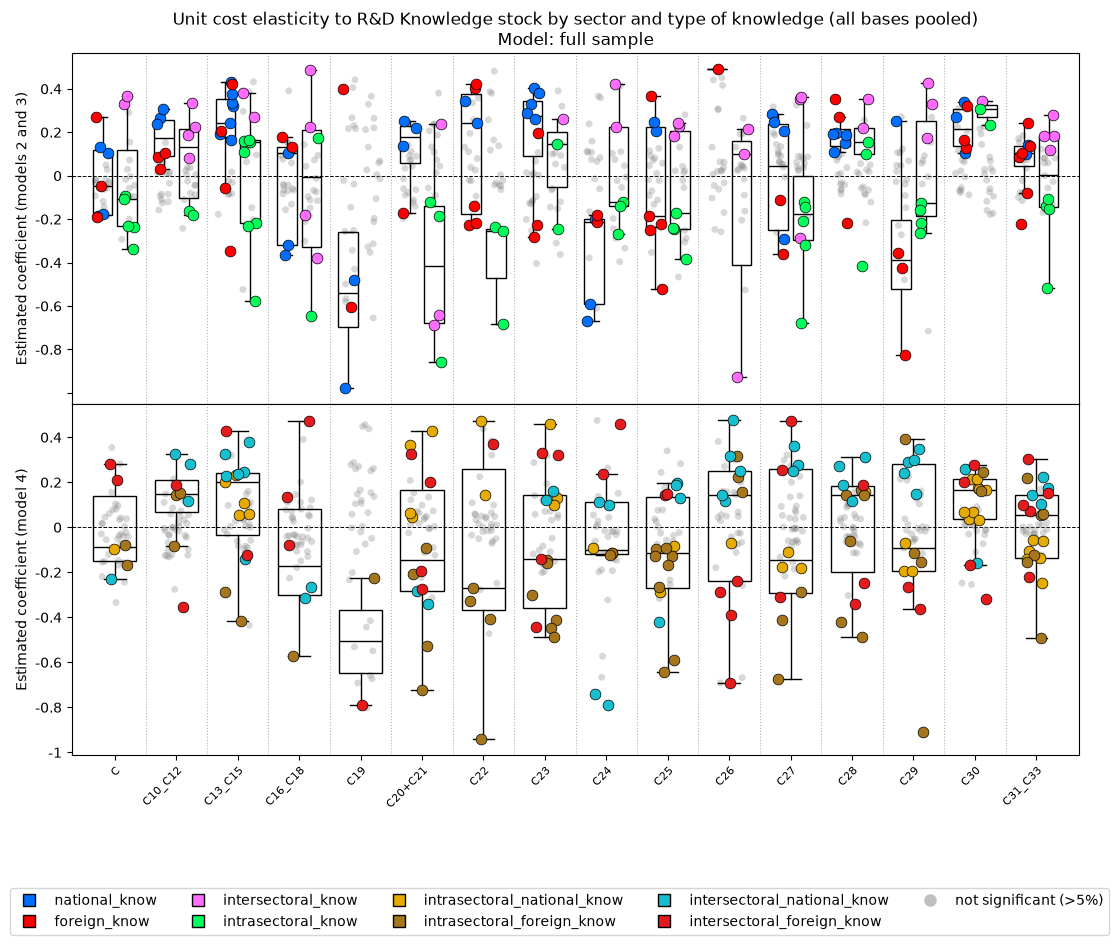

In [57]:
SECTORS = ["C", "C10_C12", "C13_C15", "C16_C18", "C19", "C20+C21", "C22", "C23",
           "C24", "C25", "C26", "C27", "C28", "C29", "C30", "C31_C33"]

STACK_TOP_VARIABLES = ["rd_D", "rd_F", "rd_X", "rd_I"]                          # models 2 and 3
STACK_BOTTOM_VARIABLES = ["same_same", "same_diff", "diff_same", "diff_diff"]   # model 4
STACK_MODEL = "all"             # Full sample only.
STACK_TOP_BOX_BY_SPEC = True    # top graph: one box per specification ((2) vs (3)), side by side
STACK_BOTTOM_BOX_BY_SPEC = False

stack_model = {"all": "rien", "tout": "rien", "rien": "rien"}[STACK_MODEL]
df_top = load_results_variables(BASES, SECTORS, STACK_TOP_VARIABLES, models=[stack_model])
df_bottom = load_results_variables(BASES, SECTORS, STACK_BOTTOM_VARIABLES, models=[stack_model])
fig, axes = plot_variables_stacked(df_top, df_bottom, bases=BASES, sectors=SECTORS,
                                   variables_top=STACK_TOP_VARIABLES, variables_bottom=STACK_BOTTOM_VARIABLES,
                                   model=stack_model, box_by_spec_top=STACK_TOP_BOX_BY_SPEC,
                                   box_by_spec_bottom=STACK_BOTTOM_BOX_BY_SPEC)
export_graph((fig, axes), os.path.join(GRAPHS_DIR, f"rd_variables_{stack_model}_stacked{TYPE_ESTIMATION}.png"))
plt.show()

## Own R&D intensity and accessible knowledge

Read `Panels_intermediaires/intensite_propre.csv` and the final panels in
`regression_panels/`. This scatter plot uses panel data independently of the
selected coefficient-table variant.

In [58]:
def compute_true_intensity(ref=None, years=None, path_wrk=PATH_WRK):
    """Read own R&D expenditure and production in current EUR million from the
    file prepared by prepa_va_STAN. The data are independent of the MRIO
    database and technology; ref is retained for compatibility."""
    d = (pd.read_csv(PANEL_CODE_DIR + "Panels_intermediaires/intensite_propre.csv")
           .rename(columns={"rd_propre_V": "rd_propre", "production_V": "production"})
           .dropna(subset=["rd_propre", "production"]))
    if years is not None:
        d = d[d["annee"].isin(years)]
    return d[["Region", "Sector", "annee", "production", "rd_propre"]]


def load_rd_total_panel(bases, path_wrk=PATH_WRK):

    frames = []
    for base in bases:
        path = RESULTS_DIR + f"regression_panels/panel_{base}_F.csv"
        if not os.path.exists(path):
            print(f"[skipped] panel not found: {path}")
            continue
        panel = pd.read_csv(path)
        for metric in ("dir", "embod"):
            col = f"rd_{metric}"
            if col not in panel.columns:
                continue
            sub = panel[["Region", "Sector", "annee", col]].rename(columns={col: "rd_total"})
            sub["base"], sub["metric"] = base, metric
            frames.append(sub)
    return pd.concat(frames, ignore_index=True)


def plot_intensity_cloud(intensity_df, rd_panel, bases, by="region", agg="sum", years=None,
                         exclude_sectors=("C", "H"), min_production=1.0, intensity_min=0.0, intensity_max=1.0,
                         metrics=METRICS,
                         x_mode="scale", log_x=False, log_y=True, label_entities=True, show_fit=False,
                         show_intensity=True, title=None, figsize=(14, 6), xtick_rotation=45):

    key, other = ("Region", "Sector") if by == "region" else ("Sector", "Region")

    d = intensity_df[~intensity_df["Sector"].isin(exclude_sectors)]
    if years is not None:
        d = d[d["annee"].isin(years)]
    pair = d.groupby(["Region", "Sector"])[["rd_propre", "production"]].sum()
    pair = pair[pair["production"] > min_production]   # drops near-zero productions (absurd intensities)
    pair["intensity"] = pair["rd_propre"] / pair["production"]
    if agg == "sum":
        ent = pair.groupby(level=key)["intensity"].sum()
    elif agg == "ratio":
        tot = pair.groupby(level=key)[["rd_propre", "production"]].sum()
        ent = tot["rd_propre"] / tot["production"]
    else:
        raise ValueError(f"agg must be 'sum' or 'ratio', got {agg!r}")
    ent = ent.sort_values()
    keep = pd.Series(True, index=ent.index)
    if intensity_min is not None:
        keep &= ent >= intensity_min
    if intensity_max is not None:
        keep &= ent <= intensity_max
    if not keep.all():
        print(f"[plot_intensity_cloud] left out (intensity outside [{intensity_min}, {intensity_max}]): "
              + ", ".join(f"{k} ({v:.2f})" for k, v in ent[~keep].items()))
    ent = ent[keep]

    panel = rd_panel[~rd_panel["Sector"].isin(exclude_sectors) & rd_panel["base"].isin(bases)]
    if years is not None:
        panel = panel[panel["annee"].isin(years)]
    panel = panel[panel["rd_total"] > 0]
    pair_mean = panel.groupby(["base", "metric", "Region", "Sector"])["rd_total"].mean()
    y = pair_mean.groupby(["base", "metric", key]).sum().reset_index()
    y = y[y[key].isin(ent.index)]
    order = [e for e in ent.index if e in set(y[key])]   # only entities that have rd_total points
    ent = ent.loc[order]
    scale = x_mode == "scale"
    xval = ent.to_dict() if scale else {name: i for i, name in enumerate(order)}

    fig, ax = plt.subplots(figsize=figsize)
    nb = len(bases)
    offset = 0.0 if scale else 0.09
    line_styles = ["-", "--", "-.", ":", (0, (5, 1)), (0, (3, 1, 1, 1))]
    fit_rows = []
    for bi, base in enumerate(bases):
        for metric in metrics:
            pts = y[(y["base"] == base) & (y["metric"] == metric)]
            if pts.empty:
                continue
            xs = pts[key].map(xval).to_numpy(dtype=float)
            ax.scatter(xs + (bi - (nb - 1) / 2) * offset, pts["rd_total"], color=METRIC_COLORS[metric],
                       marker=BASE_MARKERS[base], s=45, edgecolors="black", linewidths=0.4, zorder=3)
            if show_fit and scale and len(pts) >= 3 and len(set(xs)) > 1:
                fx = np.log10(xs) if log_x else xs
                fy = np.log10(pts["rd_total"].to_numpy()) if log_y else pts["rd_total"].to_numpy()
                slope, icpt = np.polyfit(fx, fy, 1)
                r2 = np.corrcoef(fx, fy)[0, 1] ** 2
                grid = np.linspace(fx.min(), fx.max(), 50)
                line = icpt + slope * grid
                ax.plot(10 ** grid if log_x else grid, 10 ** line if log_y else line,
                        color=METRIC_COLORS[metric], linestyle=line_styles[bi % len(line_styles)],
                        linewidth=1, alpha=0.7, zorder=2)
                fit_rows.append({"base": base, "metric": metric, "n": len(pts),
                                 "slope": slope, "R2": r2})
    if fit_rows:
        print(pd.DataFrame(fit_rows).round(3).to_string(index=False))

    if log_y:
        ax.set_yscale("log")
    ax.set_ylabel("rd_total" + (" (log scale)" if log_y else ""))
    if title is None:
        title = f"Unit cost elasticity to Knowledge stock (total_know) of each base and metric vs R&D intensity of the {by}"
    if scale:
        if log_x:
            ax.set_xscale("log")
        ax.set_xlabel(f"R&D intensity ({agg}) of each {by}" + (" (log scale)" if log_x else ""))
        if label_entities:
            for name, x in xval.items():
                ax.annotate(name, xy=(x, 1.0), xycoords=("data", "axes fraction"), xytext=(0, 3),
                            textcoords="offset points", rotation=90, ha="center", va="bottom",
                            fontsize=7, color="dimgray")
        ax.set_title(title, pad=38 if label_entities else 6)
    else:
        ax.set_xticks(range(len(order)))
        ax.set_xticklabels(order, fontsize=8, rotation=xtick_rotation, ha="right", rotation_mode="anchor")
        ax.set_xlim(-0.7, len(order) - 0.3)
        ax.set_xlabel(f"{key}s ranked by increasing R&D intensity ({agg})")
        ax.set_title(title)
        for k in range(len(order)):
            ax.axvline(k + 0.5, color="gray", linestyle=":", linewidth=0.6, alpha=0.5, zorder=0)
        if show_intensity:
            ax2 = ax.twinx()
            ax2.bar(range(len(order)), ent.to_numpy(), width=0.7, color="lightgray", alpha=0.45, zorder=0)
            ax2.set_ylim(0, ent.max() * 3)
            ax2.set_ylabel(f"R&D intensity ({agg}) - gray bars")
            ax.set_zorder(ax2.get_zorder() + 1)
            ax.patch.set_visible(False)

    from matplotlib.lines import Line2D
    handles = (
        [Line2D([0], [0], marker="s", color="none", markerfacecolor=METRIC_COLORS[m],
                markeredgecolor="black", markersize=9, label=m) for m in metrics]
        + [Line2D([0], [0], marker=BASE_MARKERS[b], color="none", markerfacecolor="white",
                  markeredgecolor="black", markersize=9, label=b) for b in bases]
    )
    ax.legend(handles=handles, loc="upper center", bbox_to_anchor=(0.5, -0.2 if not scale else -0.13),
              ncol=min(len(handles), 5))
    fig.tight_layout()
    return fig, ax


[plot_intensity_cloud] left out (intensity outside [0.0, 1.0]): C30 (1.14), C26 (1.42)


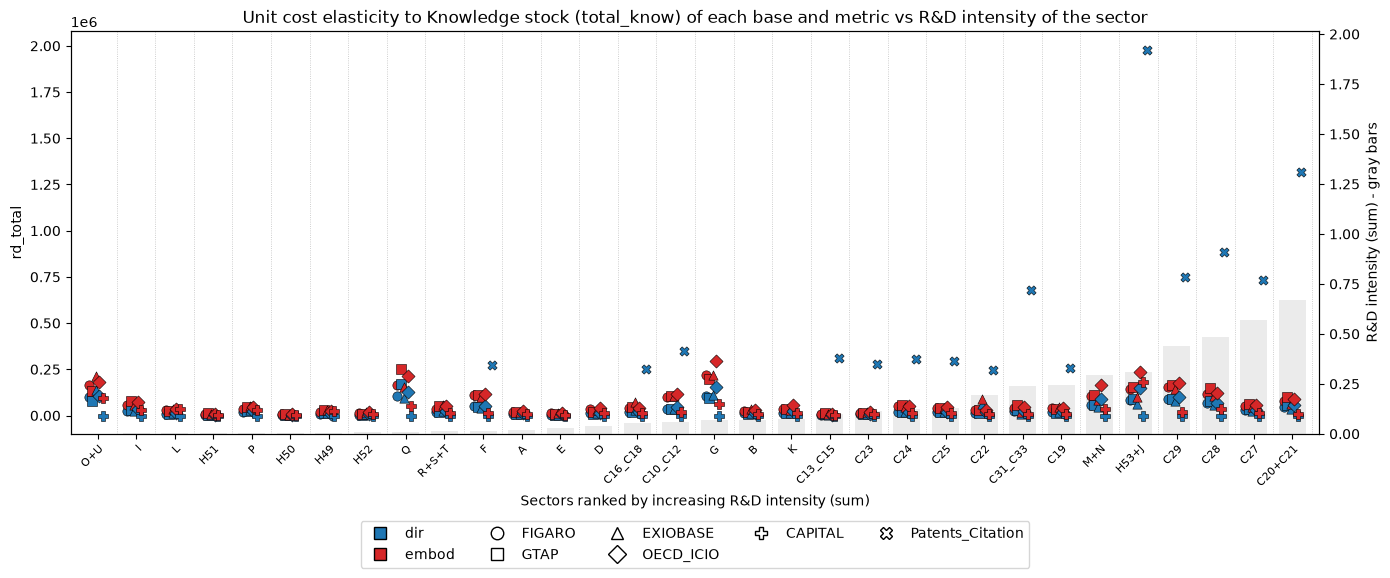

In [59]:
# This scatter plot uses the R&D panels rather than the coefficient tables:
# its input data do not depend on the selected estimation type.
INTENSITY_BY = "sector"    # "region" or "sector"
INTENSITY_AGG = "sum"      # "sum" = sum of the (region, sector) intensities ; "ratio" = total own R&D / total production
INTENSITY_YEARS = None     # None = every year, or list(range(2010, 2020))
X_MODE = "rank"           # "scale" = x-axis is the intensity itself ; "rank" = entities ranked by intensity
LOG_X = False
LOG_Y = False
SHOW_FIT = True
INTENSITY_RANGE = (0.0, 1.0)
CLOUD_BASES = ["FIGARO", "GTAP", "EXIOBASE", "OECD_ICIO", "CAPITAL", "Patents_Citation"]

df_intensity = compute_true_intensity(ref="EXIOBASE", years=INTENSITY_YEARS)
df_rd_total = load_rd_total_panel(CLOUD_BASES)
fig, ax = plot_intensity_cloud(df_intensity, df_rd_total, bases=CLOUD_BASES, by=INTENSITY_BY,
                               agg=INTENSITY_AGG, years=INTENSITY_YEARS, x_mode=X_MODE,
                               log_x=LOG_X, log_y=LOG_Y, show_fit=SHOW_FIT,
                               intensity_min=INTENSITY_RANGE[0], intensity_max=INTENSITY_RANGE[1])
export_graph((fig, ax), os.path.join(GRAPHS_DIR, f"intensity_cloud_{INTENSITY_BY}_{X_MODE}{TYPE_ESTIMATION}.png"))
plt.show()
